# Brain MRI classification
This notebook runs the classifier on Jun Cheng’s [Brain Tumor Dataset, v5 (2017)](https://doi.org/10.6084/m9.figshare.1512427.v5), shared under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). It contains 3,064 contrast-enhanced T1 MRI slices labelled glioma, meningioma, or pituitary tumor. The previewed slices have been converted to grayscale PNGs and rescaled for display. This is a learning project with no clinical validation.

Run the cells in order. The first download is about 880 MB. The same Python scripts are in the downloadable project, which uses TensorFlow 2.7. The notebook uses the TensorFlow version available in the Colab runtime.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

source = "https://raw.githubusercontent.com/psmithul/portfolio/main/public/code/brain-mri-classification/"
for name in ("prepare_figshare.py", "mri_classifier.py"):
    urlretrieve(source + name, name)

In [ ]:
from prepare_figshare import prepare

dataset = Path("figshare-mri")
if not (dataset / "dataset.json").is_file():
    prepare(dataset, Path("figshare-downloads"))
print((dataset / "dataset.json").read_text())

## MRI slices
Each column is one held-out example with its dataset label. The split puts all slices from a patient in the same group.

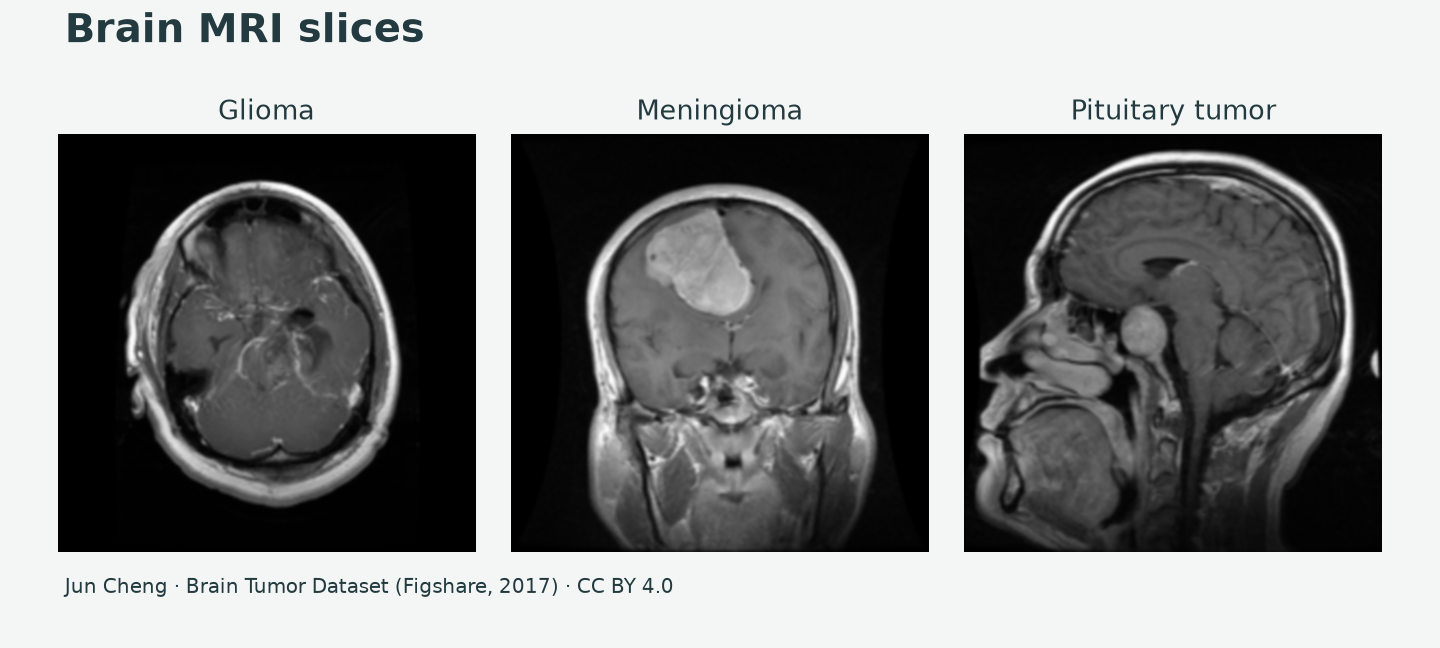

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

samples = [
    ("glioma", "2208.png", "Glioma"),
    ("meningioma", "0301.png", "Meningioma"),
    ("pituitary_tumor", "1247.png", "Pituitary tumor"),
]
background = "#f3f6f5"
ink = "#233b40"
fig, axes = plt.subplots(1, 3, figsize=(12, 5.4), facecolor=background)
fig.subplots_adjust(left=.04, right=.96, bottom=.13, top=.81, wspace=.085)
for ax, (label, filename, title) in zip(axes, samples):
    with Image.open(dataset / "test" / label / filename) as image:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="bicubic")
    ax.set_axis_off()
    ax.set_title(title, fontsize=16, color=ink, pad=9)
fig.text(.045, .935, "Brain MRI slices", fontsize=24, weight="bold", color=ink)
fig.text(.045, .085, "Jun Cheng · Brain Tumor Dataset (Figshare, 2017) · CC BY 4.0", fontsize=12, color=ink)
fig.savefig("brain-mri-figshare-slices.png", dpi=120)
plt.show()

## Train and check the classifier
The training images are shifted and rotated by small amounts, and the loss gives more weight to labels with fewer training slices. The validation and test splits use the same intensity scaling and resizing. After training, the test confusion matrix counts where each dataset label ended up.

In [ ]:
from mri_classifier import train

output = Path("brain-mri-model")
if not (output / "training.json").is_file():
    train(dataset, output, epochs=12, batch_size=32)

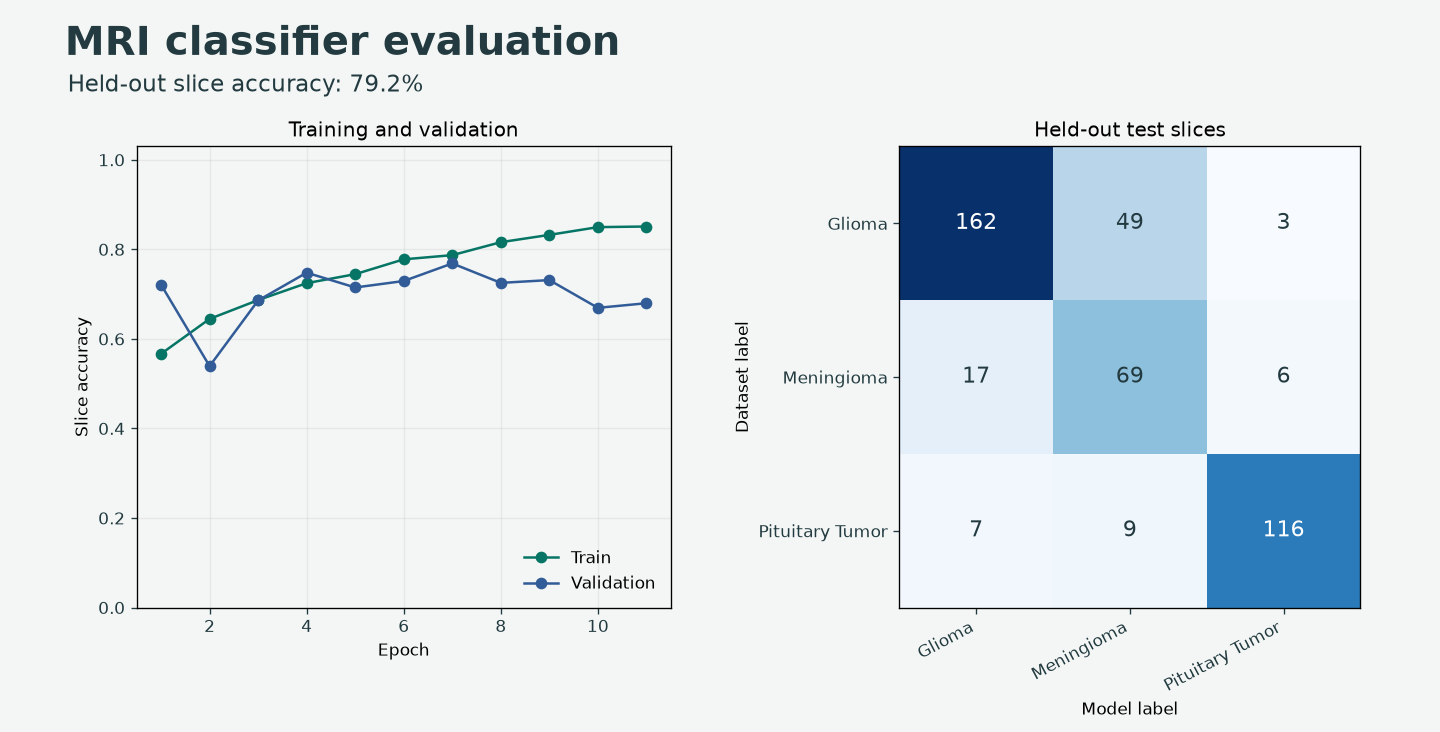

In [5]:
import json

report = json.loads((output / "training.json").read_text())
history = report["epochs"]
epochs = range(1, len(history["accuracy"]) + 1)
labels = [label.replace("_", " ").title() for label in report["classes"]]
matrix = report["confusion_matrix"]

fig, (curve, grid) = plt.subplots(1, 2, figsize=(12, 6.1), facecolor=background)
fig.subplots_adjust(left=.095, right=.97, bottom=.17, top=.8, wspace=.36)
for ax in (curve, grid):
    ax.set_facecolor(background)
    ax.tick_params(colors=ink)
curve.plot(epochs, history["accuracy"], "-o", color="#067565", label="Train")
curve.plot(epochs, history["val_accuracy"], "-o", color="#325c97", label="Validation")
curve.set(xlabel="Epoch", ylabel="Slice accuracy", ylim=(0, 1.03), title="Training and validation")
curve.grid(alpha=.2)
curve.legend(frameon=False, loc="lower right")
grid.imshow(matrix, cmap="Blues")
grid.set_xticks(range(len(labels)), labels, rotation=28, ha="right")
grid.set_yticks(range(len(labels)), labels)
grid.set(xlabel="Model label", ylabel="Dataset label", title="Held-out test slices")
limit = max(max(row) for row in matrix)
for i, row in enumerate(matrix):
    for j, value in enumerate(row):
        grid.text(j, i, value, ha="center", va="center", fontsize=13,
                  color="white" if value > limit / 2 else ink)
fig.text(.045, .925, "MRI classifier evaluation", fontsize=24, weight="bold", color=ink)
fig.text(.047, .875, f"Held-out slice accuracy: {report['test']['accuracy']:.1%}", fontsize=14, color=ink)
fig.savefig("brain-mri-figshare-results.png", dpi=120)
plt.show()

In [ ]:
from mri_classifier import predict

predict(output, dataset / "test" / "glioma" / "2208.png")